# El Niño Shoreline Project: Model Comparison

This notebook compares five approaches for predicting winter shoreline change at Southern California transects:
baselines, linear regression, a generalized additive model (GAM), a random forest, and (coming next) a gradient-boosted tree.

**Before you run it**
1. Run `build_modeling_dataset_updated.ipynb` once, so `processed/final_modeling_dataset.csv` has the new Oct–Nov → Mar–Apr target.
2. Save this notebook in the `scripts/` folder (the same folder as the other notebooks).

**How every model is tested.** Our project asks two questions, so every model is tested two ways:

| | Test 1: hold out a winter | Test 2: hold out a stretch of coastline |
|---|---|---|
| Question | Does RONI help predict next winter at transects we already know? | Do beach and wave features explain *why* some places change more? |
| Bar to beat | Transect-average baseline | Overall-average baseline |

**Rule for reading results:** RONI comparisons come from Test 1 only. Beach/wave comparisons come from Test 2 only.

---
# Section 1: Setup and data

### 1a. Settings
Every choice that might change lives here. If the dataset file is renamed, or the team picks a different outlier cutoff, change it in this cell and rerun.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent           # assumes this notebook lives in scripts/
DATA_PATH = ROOT_DIR / "processed" / "final_modeling_dataset.csv"

TARGET = "shoreline_change_m"          # Mar–Apr average position minus Oct–Nov average position
OUTLIER_LIMIT_M = 50                   # drop rows where |change| is above this

BEACH_FEATURES = ["BeachWidth_m", "beach_slope", "shore_orientation_sin", "shore_orientation_cos"]
WAVE_FEATURES  = ["winter_wave_power", "wave_dir_sin", "wave_dir_cos"]   # Oct–Apr averages

FEATURE_SETS = {
    "beach":               BEACH_FEATURES,
    "beach + wave":        BEACH_FEATURES + WAVE_FEATURES,
    "beach + wave + RONI": BEACH_FEATURES + WAVE_FEATURES + ["RONI"],
}

### 1b. Load the data and check it's the new dataset
**Expected:** 60,864 rows, 3,220 transects, 21 winters, 740 missing `beach_slope` values, mean change about −7.17 m.
The `assert` stops the notebook with a clear message if the old Dec–Feb file is loaded by mistake.

In [2]:
df = pd.read_csv(DATA_PATH)

# delete this when updated dataset is pushed to github 
assert {"pre_winter", "post_winter"}.issubset(df.columns), \
    "This looks like the old Dec–Feb dataset. Run build_modeling_dataset_updated.ipynb first."

print("Rows:", len(df))
print("Transects:", df["transect_id"].nunique())
print("Winters:", df["winter"].nunique())
print()
print("Missing values:")
print(df[FEATURE_SETS["beach + wave + RONI"] + [TARGET]].isna().sum())
print()
print(df[TARGET].describe().round(2))

Rows: 60864
Transects: 3220
Winters: 21

Missing values:
BeachWidth_m               0
beach_slope              740
shore_orientation_sin      0
shore_orientation_cos      0
winter_wave_power          0
wave_dir_sin               0
wave_dir_cos               0
RONI                       0
shoreline_change_m         0
dtype: int64

count    60864.00
mean        -7.17
std         11.53
min       -118.69
25%        -12.88
50%         -6.35
75%         -0.77
max        133.07
Name: shoreline_change_m, dtype: float64


### 1c. Remove outliers
Rows with more than ±50 m of change in one winter are most likely satellite detection errors.
**Expected:** 280 rows removed (0.46%), clustered in a few coastal sections, leaving 60,584 rows.

### Step 1: Mark each row as an outlier (True) or not (False)
### An outlier is a change bigger than 50 m in either direction

In [3]:
is_outlier = df[TARGET].abs() > OUTLIER_LIMIT_M


### Step 2: Count the outliers

In [5]:
number_of_outliers = is_outlier.sum()
total_rows = len(df)
percent = number_of_outliers / total_rows * 100

print("Outlier rows:", number_of_outliers)
print("Percent of all rows:", round(percent, 2), "%")

Outlier rows: 280
Percent of all rows: 0.46 %


### Step 3: See which sections have the most outliers


In [6]:
outlier_rows = df[is_outlier]
outlier_sections = outlier_rows["transect_id"].str[:11]   # first 11 characters = section name
print("Sections with the most outliers:")
print(outlier_sections.value_counts().head(5))

Sections with the most outliers:
transect_id
usa_CA_0026    45
usa_CA_0088    40
usa_CA_0084    31
usa_CA_0002    25
usa_CA_0051    23
Name: count, dtype: int64


### Step 4: Keep only the rows that are NOT outliers


In [7]:
df = df[is_outlier == False]
df = df.reset_index(drop=True)

print("Rows after removing outliers:", len(df))

Rows after removing outliers: 60584


### 1d. Target, groups, and coastal sections
`section` is the coastal section each transect belongs to (for example, `usa_CA_0026-0004` is in section `usa_CA_0026`).
Test 2 holds out whole sections, so a transect and its neighbors are always hidden together.

**Columns never used as features:**

| Column | Why |
|---|---|
| `pre_winter`, `post_winter` | The target is built from them (post − pre), so they would leak the answer |
| `pre_observation_count`, `post_observation_count` | Data quality, not beach properties |
| `transect_id`, `winter`, `section` | Labels, not measurements |

Label the target variable and group coastline into sections for test 2 

In [8]:
y = df[TARGET]
df["section"] = df["transect_id"].str[:11]

print("Coastal sections:", df["section"].nunique())

Coastal sections: 110


---
# Section 2: Testing setup and baselines

### 2a. The two tests
- **Test 1** (`LeaveOneGroupOut` on winter): 21 folds. Each fold trains on 20 winters and predicts the 21st, at every transect.
- **Test 2** (`GroupKFold` on section): 10 folds. The 110 sections are split into 10 groups; each fold hides one group in every winter.

Import necessary libraries with tools and metrics 

In [30]:
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error


For each test group, hold appropriate test data out (for training)

Test 1: Hold out one winter at a time

In [31]:
test1_splitter = LeaveOneGroupOut()
test1_groups = df["winter"] # we hold out one winter every test 

Test 2: Hold out groups of coastal section

In [32]:
test2_splitter = GroupKFold(n_splits=10)
test2_groups = df["section"]

Print Results

In [33]:
print("Test 1 number of folds:", test1_splitter.get_n_splits(groups=test1_groups))
print("Test 2 number of folds:", test2_splitter.get_n_splits(groups=test2_groups))

Test 1 number of folds: 21
Test 2 number of folds: 10


Test 1: Look at the first fold

In [34]:
test1_folds = list(test1_splitter.split(df, y, test1_groups))   # all 21 folds
train_rows, test_rows = test1_folds[0]                            # take the first one

test_data = df.iloc[test_rows]          # the rows hidden in this fold
print("Test 1, fold 1")
print("  Hidden winter:", test_data["winter"].unique())
print("  Training rows:", len(train_rows))
print("  Test rows:", len(test_rows))

Test 1, fold 1
  Hidden winter: <ArrowStringArray>
['2000-2001']
Length: 1, dtype: str
  Training rows: 58266
  Test rows: 2318


Test 2: look at the first fold 

In [35]:
test2_folds = list(test2_splitter.split(df, y, test2_groups))   # all 10 folds
train_rows, test_rows = test2_folds[0]

test_data = df.iloc[test_rows]
print("Test 2, fold 1")
print("  Number of hidden sections:", test_data["section"].nunique())
print("  Training rows:", len(train_rows))
print("  Test rows:", len(test_rows))

Test 2, fold 1
  Number of hidden sections: 10
  Training rows: 54510
  Test rows: 6074


Bundle tests together for the evaluate() function used later on 

In [36]:
SPLITS = {
    "Test 1: new winter":    (test1_splitter, test1_groups),
    "Test 2: new coastline": (test2_splitter, test2_groups),
}

### 2b. One function to evaluate any model
Every model goes through `evaluate()`, so every model is tested exactly the same way.

`cross_val_predict` returns one prediction per row, each made by a model that never saw that row's held-out group.
We then score all predictions together (pooled R² and MAE), rather than averaging per-fold scores. Inside a single winter every row has the same RONI, so per-winter scores would penalize RONI unfairly.

Create variables to hold our results and predictions

In [37]:
results = {}       # scores for every model and test
predictions = {}   # held-out predictions, kept for plots later

Create the evaluate function so every model can be tested the same way. 

Evaluate parameters  - 
- name: A label we choose 
- model: the model we are using to train 
- features: list of columns the model will use 
- tests (optional): which tests to run. Used for section 7
- pass_groups (optional): needed for gradient boost model 

In [38]:
def evaluate(name, model, features, tests=None, pass_groups=False):
    for test_name in SPLITS:
        splitter, groups = SPLITS[test_name]

        # Skip this test if we asked for only certain tests (used in Section 7)
        if tests is not None and test_name not in tests:
            continue

        # The gradient-boosted tree (Section 6) needs the group labels for its tuning
        if pass_groups:
            extra = {"groups": groups}
        else:
            extra = None

        # Train and predict on every fold: one held-out prediction per row
        pred = cross_val_predict(model, df[features], y, groups=groups, cv=splitter, params=extra)

        # Save the predictions and the scores
        predictions[(name, test_name)] = pred
        results[(name, test_name)] = {
            "R²": r2_score(y, pred),
            "MAE (m)": mean_absolute_error(y, pred),
        }

    return show_results()

In [39]:
def show_results():
    table = pd.DataFrame(results).T          # one row per model and test
    table.index.names = ["Model", "Test"]
    return table.round(3)

### 2c. Two baselines
- **Overall average:** predicts the training-set average for every row. It ignores its input; RONI is passed only because scikit-learn requires a column.
- **Transect average:** predicts each transect's own average change from the training data. scikit-learn has no built-in version, so we write a tiny one. For a transect it has never seen (Test 2), it falls back to the overall average.

**Expected:**

| Model | Test 1 R² | Test 1 MAE | Test 2 R² | Test 2 MAE |
|---|---|---|---|---|
| Overall average | −0.008 | 7.99 | −0.009 | 8.00 |
| Transect average | 0.459 | 5.85 | −0.009 | 8.00 |

The transect average is the real bar for the RONI question: about 46% of the variation is consistent location behavior.

In [40]:
from sklearn.dummy import DummyRegressor
from sklearn.base import BaseEstimator, RegressorMixin

We create the TrasectAverage to look similar to other model classes with scikit-learn (with a 'fit' and 'predict' method)

In [41]:
class TransectAverage(BaseEstimator, RegressorMixin):

    def fit(self, X, y):
        # Step 1: calculate each transect's average change in the training data
        # Create a new dataframe with columns transect_id and change
        training = pd.DataFrame({"transect_id": X["transect_id"].values, "change": np.asarray(y)})
        self.averages_ = training.groupby("transect_id")["change"].mean()  # get the averages of each transect as a Pandas series
        self.overall_ = training["change"].mean()   # backup for transects never seen
        return self

    def predict(self, X):
        # Step 2: look up each row's transect average
        predictions = X["transect_id"].map(self.averages_)
        # A transect that wasn't in the training data gets the overall average
        predictions = predictions.fillna(self.overall_)
        return predictions.to_numpy()

In [42]:
print("Overall average change:", round(y.mean(), 2), "m")

Overall average change: -7.1 m


In [43]:
transect_averages = df.groupby("transect_id")[TARGET].mean()
print("Number of transects:", len(transect_averages))
print(transect_averages.head())
print(transect_averages.describe().round(2))

Number of transects: 3220
transect_id
usa_CA_0001-0000   -19.951583
usa_CA_0001-0001   -20.819188
usa_CA_0001-0002   -20.040362
usa_CA_0001-0003   -20.497748
usa_CA_0001-0004   -23.399450
Name: shoreline_change_m, dtype: float64
count    3220.00
mean       -7.24
std         7.80
min       -40.60
25%       -11.51
50%        -6.38
75%        -2.49
max        24.46
Name: shoreline_change_m, dtype: float64


In [44]:
evaluate("Baseline: overall average",  DummyRegressor(strategy="mean"), ["RONI"])
evaluate("Baseline: transect average", TransectAverage(),               ["transect_id"])

R²  MAE (m)
Model                      Test                                 
Baseline: overall average  Test 1: new winter    -0.008    7.994
                           Test 2: new coastline -0.009    7.999
Baseline: transect average Test 1: new winter     0.459    5.849
                           Test 2: new coastline -0.009    7.999

---
# Section 3: Linear regression

### 3a–3b. Pipeline and results
The pipeline fills missing slopes with the median and standardizes features **inside each fold**, using only that fold's training data, so the held-out data never influences preprocessing.
Standardizing doesn't change predictions; it makes coefficients comparable.

**Expected (Test 1 R²):** beach 0.028 · beach + wave 0.052 · + RONI 0.044.

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

def make_linear():
    return make_pipeline(
        SimpleImputer(strategy="median"), # handles missing values
        StandardScaler(),
        LinearRegression(),
    )

for set_name, features in FEATURE_SETS.items():
    evaluate(f"Linear: {set_name}", make_linear(), features)

show_results()

R²  MAE (m)
Model                       Test                                 
Baseline: overall average   Test 1: new winter    -0.008    7.994
                            Test 2: new coastline -0.009    7.999
Baseline: transect average  Test 1: new winter     0.459    5.849
                            Test 2: new coastline -0.009    7.999
Linear: beach               Test 1: new winter     0.028    7.831
                            Test 2: new coastline  0.019    7.870
Linear: beach + wave        Test 1: new winter     0.052    7.762
                            Test 2: new coastline  0.037    7.822
Linear: beach + wave + RONI Test 1: new winter     0.044    7.806
                            Test 2: new coastline  0.037    7.826

### 3c. Standardized coefficients
Fit once on all data to **describe** relationships (the scores above are the honest performance numbers).
Each coefficient is the change in meters per one standard deviation of that feature.

Caution: wave direction and shoreline orientation are strongly related, so the model can split credit between them unpredictably. Don't over-read individual coefficients; permutation importance (Section 8) handles this better.

In [18]:
full = FEATURE_SETS["beach + wave + RONI"]
lin = make_linear().fit(df[full], y)

coefs = pd.Series(lin[-1].coef_, index=full).sort_values(key=abs, ascending=False)
coefs.round(3)

wave_dir_cos            -3.971
shore_orientation_cos    2.230
beach_slope              1.247
shore_orientation_sin   -1.096
winter_wave_power       -0.922
BeachWidth_m            -0.640
RONI                    -0.400
wave_dir_sin            -0.387
dtype: float64

---
# Section 4: Generalized additive model (GAM)

### 4a–4b. Recipe and results
A GAM gives each feature its own smooth curve and adds the curves together. It can bend, but each feature's effect stays separate, so it remains interpretable.
- `SplineTransformer` turns each feature into smooth curve pieces joined at 5 knots; `knots="quantile"` places knots where the data is.
- `Ridge` penalizes large coefficients so curves don't chase noise (larger `alpha` means smoother).

**Expected (Test 1 R²):** beach 0.082 · beach + wave 0.104 · + RONI 0.099.

In [19]:
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import Ridge

def make_gam():
    return make_pipeline(
        SimpleImputer(strategy="median"),      # fill the missing slopes
        SplineTransformer(knots="quantile"),   # turn each feature into a smooth curve
        Ridge(),                               # fit the curves, keeping them smooth
    )

for set_name, features in FEATURE_SETS.items():
    evaluate(f"GAM: {set_name}", make_gam(), features)

show_results()

R²  MAE (m)
Model                       Test                                 
Baseline: overall average   Test 1: new winter    -0.008    7.994
                            Test 2: new coastline -0.009    7.999
Baseline: transect average  Test 1: new winter     0.459    5.849
                            Test 2: new coastline -0.009    7.999
Linear: beach               Test 1: new winter     0.028    7.831
                            Test 2: new coastline  0.019    7.870
Linear: beach + wave        Test 1: new winter     0.052    7.762
                            Test 2: new coastline  0.037    7.822
Linear: beach + wave + RONI Test 1: new winter     0.044    7.806
                            Test 2: new coastline  0.037    7.826
GAM: beach                  Test 1: new winter     0.082    7.577
                            Test 2: new coastline  0.051    7.709
GAM: beach + wave           Test 1: new winter     0.104    7.516
                            Test 2: new coastline  0.044    7.777
GAM: beach + wave + RONI    Test 1: new winter     0.099    7.562
                            Test 2: new coastline  0.074    7.629

### 4c. The shape the GAM gives RONI
Predictions for a "typical" transect (every feature at its median), varying only RONI, with each winter's actual average change as gray dots.

The curve bends to pass near individual winters (the dip near RONI 1.5 is driven mostly by 2009–10; the rise at 2.1 is a single winter, 2015–16). That's memorizing winters rather than learning a smooth El Niño effect, which is why RONI doesn't help in Test 1.

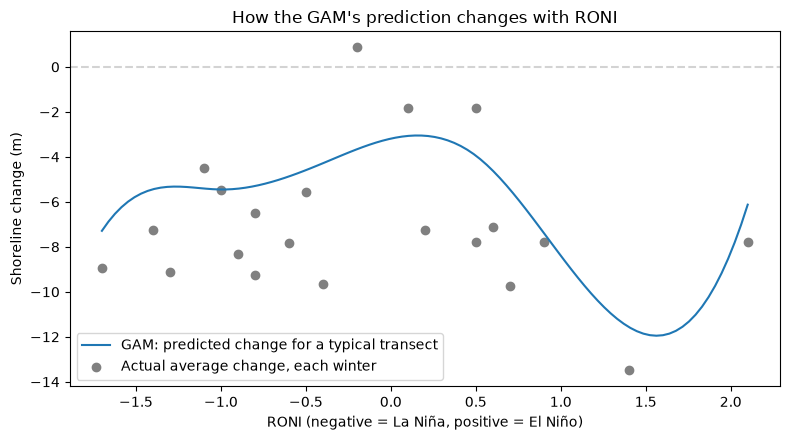

In [20]:
gam = make_gam().fit(df[full], y)   # fit on all data, for interpretation only

roni_grid = np.linspace(df["RONI"].min(), df["RONI"].max(), 100)
X_grid = pd.DataFrame([df[full].median()] * len(roni_grid)).reset_index(drop=True)
X_grid["RONI"] = roni_grid

winter_means = df.groupby("winter").agg(RONI=("RONI", "first"), mean_change=(TARGET, "mean"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(roni_grid, gam.predict(X_grid), label="GAM: predicted change for a typical transect")
ax.scatter(winter_means["RONI"], winter_means["mean_change"], color="gray", label="Actual average change, each winter")
ax.axhline(0, linestyle="--", color="lightgray")
ax.set_xlabel("RONI (negative = La Niña, positive = El Niño)")
ax.set_ylabel("Shoreline change (m)")
ax.set_title("How the GAM's prediction changes with RONI")
ax.legend()
plt.tight_layout()
plt.show()

---
# Section 5: Random forest

A random forest averages many decision trees, each trained on a random sample of rows and considering a random subset of features at each split.
`min_samples_leaf=50` makes every prediction an average over at least 50 rows, which matters with a noisy target.

**This cell is slow** (several minutes, since it runs both tests). `n_estimators=100` keeps it manageable; more trees change results very little.

**How to read it:** every transect has a unique combination of feature values, so in Test 1 the forest can recognize transects and predict their usual change. Compare it with the **transect-average baseline**, not the overall average. Only Test 2 shows what the features themselves explain.

In [21]:
from sklearn.ensemble import RandomForestRegressor

def make_rf(min_samples_leaf=50): #max number of rows in each leaf
    return make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=100, # number of trees in the forest 
            min_samples_leaf=min_samples_leaf,
            max_features=0.5, # each tree considers half of features
            n_jobs=-1, # CPU cores (speed)
            random_state=42,
        ),
    )

for set_name, features in FEATURE_SETS.items():
    evaluate(f"RF: {set_name}", make_rf(), features)

show_results()

R²  MAE (m)
Model                       Test                                 
Baseline: overall average   Test 1: new winter    -0.008    7.994
                            Test 2: new coastline -0.009    7.999
Baseline: transect average  Test 1: new winter     0.459    5.849
                            Test 2: new coastline -0.009    7.999
Linear: beach               Test 1: new winter     0.028    7.831
                            Test 2: new coastline  0.019    7.870
Linear: beach + wave        Test 1: new winter     0.052    7.762
                            Test 2: new coastline  0.037    7.822
Linear: beach + wave + RONI Test 1: new winter     0.044    7.806
                            Test 2: new coastline  0.037    7.826
GAM: beach                  Test 1: new winter     0.082    7.577
                            Test 2: new coastline  0.051    7.709
GAM: beach + wave           Test 1: new winter     0.104    7.516
                            Test 2: new coastline  0.044    7.777
GAM: beach + wave + RONI    Test 1: new winter     0.099    7.562
                            Test 2: new coastline  0.074    7.629
RF: beach                   Test 1: new winter     0.341    6.406
                            Test 2: new coastline -0.026    8.070
RF: beach + wave            Test 1: new winter     0.403    6.112
                            Test 2: new coastline  0.001    8.002
RF: beach + wave + RONI     Test 1: new winter     0.245    6.935
                            Test 2: new coastline  0.071    7.637

---
# Section 6: Gradient-boosted tree

### 6a. What it is
A gradient-boosted tree builds small trees **one after another**. Each new tree predicts the errors the previous trees left behind, and a small fraction of its prediction (the *learning rate*) is added to the total.

We use scikit-learn's `HistGradientBoostingRegressor`. It's fast on 60,000 rows and handles the missing `beach_slope` values on its own, so no imputer is needed.

| Setting | What it controls | Our choice |
|---|---|---|
| `learning_rate` | How much each tree contributes. Smaller is more careful but needs more trees | 0.05 |
| `max_iter` + early stopping | Maximum number of trees. Early stopping halts when a held-back 10% of the training rows stops improving | up to 300 |
| `max_leaf_nodes` | How complex each tree can be | **tuned:** 15 or 31 |
| `min_samples_leaf` | Minimum rows per leaf. Larger values stop the model from chasing noise | **tuned:** 100 or 500 |

### 6b. Tuning without peeking
If we picked settings by looking at the test scores, the test would no longer be a fair exam. So tuning happens **inside each training fold**, using only that fold's training data:

1. The outer test (Test 1 or Test 2) sets one group aside, untouched.
2. Inside the remaining data, `GridSearchCV` tries all 4 setting combinations, scoring each with its own inner 3-fold split **by the same kind of group** (winters in Test 1, sections in Test 2).
3. The best combination is retrained on all the fold's training data and only then predicts the held-out group.

This is called **nested cross-validation**. `pass_groups=True` hands the group labels to the inner search so it splits by winter or section too, not randomly.

**Expected:** a few minutes. Compare Test 1 with the **transect-average baseline** and Test 2 with the overall average, as for the random forest.

In [22]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

GBT_GRID = {
    "max_leaf_nodes":   [15, 31],
    "min_samples_leaf": [100, 500],
}

def make_gbt():
    base = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    )
    return GridSearchCV(base, GBT_GRID, cv=GroupKFold(n_splits=3), scoring="neg_mean_absolute_error")

for set_name, features in FEATURE_SETS.items():
    evaluate(f"GBT: {set_name}", make_gbt(), features, pass_groups=True)

show_results()

R²  MAE (m)
Model                       Test                                 
Baseline: overall average   Test 1: new winter    -0.008    7.994
                            Test 2: new coastline -0.009    7.999
Baseline: transect average  Test 1: new winter     0.459    5.849
                            Test 2: new coastline -0.009    7.999
Linear: beach               Test 1: new winter     0.028    7.831
                            Test 2: new coastline  0.019    7.870
Linear: beach + wave        Test 1: new winter     0.052    7.762
                            Test 2: new coastline  0.037    7.822
Linear: beach + wave + RONI Test 1: new winter     0.044    7.806
                            Test 2: new coastline  0.037    7.826
GAM: beach                  Test 1: new winter     0.082    7.577
                            Test 2: new coastline  0.051    7.709
GAM: beach + wave           Test 1: new winter     0.104    7.516
                            Test 2: new coastline  0.044    7.777
GAM: beach + wave + RONI    Test 1: new winter     0.099    7.562
                            Test 2: new coastline  0.074    7.629
RF: beach                   Test 1: new winter     0.341    6.406
                            Test 2: new coastline -0.026    8.070
RF: beach + wave            Test 1: new winter     0.403    6.112
                            Test 2: new coastline  0.001    8.002
RF: beach + wave + RONI     Test 1: new winter     0.245    6.935
                            Test 2: new coastline  0.071    7.637
GBT: beach                  Test 1: new winter     0.331    6.488
                            Test 2: new coastline -0.010    7.968
GBT: beach + wave           Test 1: new winter     0.404    6.144
                            Test 2: new coastline  0.002    7.993
GBT: beach + wave + RONI    Test 1: new winter     0.303    6.726
                            Test 2: new coastline  0.072    7.643

### 6c. Which settings won?
For reference, run the same search once on all the data with each test's grouping. This shows which settings the tuning tends to prefer and how many trees early stopping kept. (The scores above are the honest performance numbers.)

If early stopping keeps all 300 trees, it never triggered. That's expected here: early stopping checks a random 10% of the training rows, and those rows come from the same transects the trees are learning from. So recognizing transects keeps "improving" the check. This doesn't affect the honesty of the test scores, which always come from groups the model never saw.

In [23]:
features = FEATURE_SETS["beach + wave"]
for test_name, (cv, grp) in SPLITS.items():
    search = make_gbt().fit(df[features], y, groups=grp)
    print(f"{test_name}: best settings {search.best_params_}, "
          f"trees kept by early stopping: {search.best_estimator_.n_iter_}")

Test 1: new winter: best settings {'max_leaf_nodes': 31, 'min_samples_leaf': 100}, trees kept by early stopping: 300
Test 2: new coastline: best settings {'max_leaf_nodes': 15, 'min_samples_leaf': 100}, trees kept by early stopping: 300


In [24]:
features = FEATURE_SETS["beach + wave"]

# Test 1: tune with winters kept together
search1 = make_gbt().fit(df[features], y, groups=df["winter"])
print("Test 1 best settings:", search1.best_params_)
print("Test 1 trees used:", search1.best_estimator_.n_iter_)

# Test 2: tune with coastal sections kept together
search2 = make_gbt().fit(df[features], y, groups=df["section"])
print("Test 2 best settings:", search2.best_params_)
print("Test 2 trees used:", search2.best_estimator_.n_iter_)

Test 1 best settings: {'max_leaf_nodes': 31, 'min_samples_leaf': 100}
Test 1 trees used: 300
Test 2 best settings: {'max_leaf_nodes': 15, 'min_samples_leaf': 100}
Test 2 trees used: 300


---
# Section 7: Does RONI push a transect above or below its own normal?

Sections 3–6 showed the real bar in Test 1 is each transect's own average. But none of those models **combines** that history with RONI. This section asks the cleanest version of the research question:

> Given what a transect normally does, does El Niño push this winter above or below normal?

`TransectAveragePlus` does it in two steps, inside each training fold:
1. Calculate each transect's average change (the transect-average baseline).
2. Fit a second model to the **leftovers**: each row's change minus its transect's average. If RONI explains whether a winter is better or worse than normal, it will show up here.

Three versions:
- **+ linear RONI:** one shared El Niño effect for every transect.
- **+ GBT beach + wave (no RONI):** a control. Beach features never change from winter to winter, so this should add nothing. If it did, something would be wrong.
- **+ GBT beach + wave + RONI:** lets El Niño's effect differ by beach type (for example, by orientation).

Only Test 1 is used: in Test 2 the transects are unseen, so there's no "own average" to start from.

In [25]:
from sklearn.base import clone

class TransectAveragePlus(BaseEstimator, RegressorMixin):
    """Transect average + a second model fit to each row's difference from its transect's average."""
    def __init__(self, model=None, features=None):
        self.model = model
        self.features = features

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.means_ = y.groupby(X["transect_id"]).mean()
        self.overall_ = float(y.mean())
        leftovers = y - X["transect_id"].map(self.means_)
        self.model_ = clone(self.model).fit(X[self.features], leftovers)
        return self

    def predict(self, X):
        normal = X["transect_id"].map(self.means_).fillna(self.overall_).to_numpy()
        return normal + self.model_.predict(X[self.features])

small_gbt = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                          min_samples_leaf=500, random_state=42)
TEST_1 = ["Test 1: new winter"]
BEACH_WAVE = FEATURE_SETS["beach + wave"]
BEACH_WAVE_RONI = FEATURE_SETS["beach + wave + RONI"]

evaluate("Transect average + linear RONI",
         TransectAveragePlus(LinearRegression(), ["RONI"]),
         ["transect_id", "RONI"], tests=TEST_1)
evaluate("Transect average + GBT beach + wave (control)",
         TransectAveragePlus(small_gbt, BEACH_WAVE),
         ["transect_id"] + BEACH_WAVE, tests=TEST_1)
evaluate("Transect average + GBT beach + wave + RONI",
         TransectAveragePlus(small_gbt, BEACH_WAVE_RONI),
         ["transect_id"] + BEACH_WAVE_RONI, tests=TEST_1)

show_results()

R²  \
Model                                         Test                           
Baseline: overall average                     Test 1: new winter    -0.008   
                                              Test 2: new coastline -0.009   
Baseline: transect average                    Test 1: new winter     0.459   
                                              Test 2: new coastline -0.009   
Linear: beach                                 Test 1: new winter     0.028   
                                              Test 2: new coastline  0.019   
Linear: beach + wave                          Test 1: new winter     0.052   
                                              Test 2: new coastline  0.037   
Linear: beach + wave + RONI                   Test 1: new winter     0.044   
                                              Test 2: new coastline  0.037   
GAM: beach                                    Test 1: new winter     0.082   
                                              Test 2: new coastline  0.051   
GAM: beach + wave                             Test 1: new winter     0.104   
                                              Test 2: new coastline  0.044   
GAM: beach + wave + RONI                      Test 1: new winter     0.099   
                                              Test 2: new coastline  0.074   
RF: beach                                     Test 1: new winter     0.341   
                                              Test 2: new coastline -0.026   
RF: beach + wave                              Test 1: new winter     0.403   
                                              Test 2: new coastline  0.001   
RF: beach + wave + RONI                       Test 1: new winter     0.245   
                                              Test 2: new coastline  0.071   
GBT: beach                                    Test 1: new winter     0.331   
                                              Test 2: new coastline -0.010   
GBT: beach + wave                             Test 1: new winter     0.404   
                                              Test 2: new coastline  0.002   
GBT: beach + wave + RONI                      Test 1: new winter     0.303   
                                              Test 2: new coastline  0.072   
Transect average + linear RONI                Test 1: new winter     0.452   
Transect average + GBT beach + wave (control) Test 1: new winter     0.460   
Transect average + GBT beach + wave + RONI    Test 1: new winter     0.377   

                                                                     MAE (m)  
Model                                         Test                            
Baseline: overall average                     Test 1: new winter       7.994  
                                              Test 2: new coastline    7.999  
Baseline: transect average                    Test 1: new winter       5.849  
                                              Test 2: new coastline    7.999  
Linear: beach                                 Test 1: new winter       7.831  
                                              Test 2: new coastline    7.870  
Linear: beach + wave                          Test 1: new winter       7.762  
                                              Test 2: new coastline    7.822  
Linear: beach + wave + RONI                   Test 1: new winter       7.806  
                                              Test 2: new coastline    7.826  
GAM: beach                                    Test 1: new winter       7.577  
                                              Test 2: new coastline    7.709  
GAM: beach + wave                             Test 1: new winter       7.516  
                                              Test 2: new coastline    7.777  
GAM: beach + wave + RONI                      Test 1: new winter       7.562  
                                              Test 2: new coastline    7.629  
RF: beach                                     Test 1: new winter       6.40

---
# Section 8: Final comparison and interpretation

### 8a. The two questions, side by side
Each question gets its own table, using only the test that answers it.

In [26]:
all_results = pd.DataFrame(results).T
all_results.index.names = ["Model", "Test"]

# Question 1 (Test 1): does adding RONI help predict a new winter?
pairs = {
    "Transect average":       ("Baseline: transect average",  "Transect average + linear RONI"),
    "Transect average + GBT": ("Transect average + GBT beach + wave (control)", "Transect average + GBT beach + wave + RONI"),
    "Linear":                 ("Linear: beach + wave", "Linear: beach + wave + RONI"),
    "GAM":                    ("GAM: beach + wave",    "GAM: beach + wave + RONI"),
    "Random forest":          ("RF: beach + wave",     "RF: beach + wave + RONI"),
    "GBT":                    ("GBT: beach + wave",    "GBT: beach + wave + RONI"),
}
t1 = "Test 1: new winter"
q1 = pd.DataFrame({
    family: {
        "R² without RONI": all_results.loc[(without, t1), "R²"],
        "R² with RONI":    all_results.loc[(with_, t1), "R²"],
    }
    for family, (without, with_) in pairs.items()
}).T
q1["Change from adding RONI"] = q1["R² with RONI"] - q1["R² without RONI"]
print("QUESTION 1 (Test 1: new winter). Does RONI help? Bar to beat: transect average, R² =",
      round(all_results.loc[("Baseline: transect average", t1), "R²"], 3))
print(q1.round(3).to_string())

# Question 2 (Test 2): do beach and wave features explain unfamiliar coastline? (no RONI rows)
t2 = "Test 2: new coastline"
q2_models = ["Baseline: overall average"] + [f"{m}: {s}" for m in ["Linear", "GAM", "RF", "GBT"] for s in ["beach", "beach + wave"]]
q2 = all_results.xs(t2, level="Test").loc[q2_models]
print()
print("QUESTION 2 (Test 2: new coastline). Do beach and wave features explain differences between places?")
print(q2.round(3).to_string())

QUESTION 1 (Test 1: new winter). Does RONI help? Bar to beat: transect average, R² = 0.459
                        R² without RONI  R² with RONI  Change from adding RONI
Transect average                  0.459         0.452                   -0.007
Transect average + GBT            0.460         0.377                   -0.082
Linear                            0.052         0.044                   -0.007
GAM                               0.104         0.099                   -0.006
Random forest                     0.403         0.245                   -0.158
GBT                               0.404         0.303                   -0.101

QUESTION 2 (Test 2: new coastline). Do beach and wave features explain differences between places?
                              R²  MAE (m)
Model                                    
Baseline: overall average -0.009    7.999
Linear: beach              0.019    7.870
Linear: beach + wave       0.037    7.822
GAM: beach                 0.051    7.709
GAM:

### 8b. Picture of both answers
Left: how much adding RONI changes Test 1 R² for each model (below zero means RONI hurts). Right: Test 2 R² with beach + wave features.

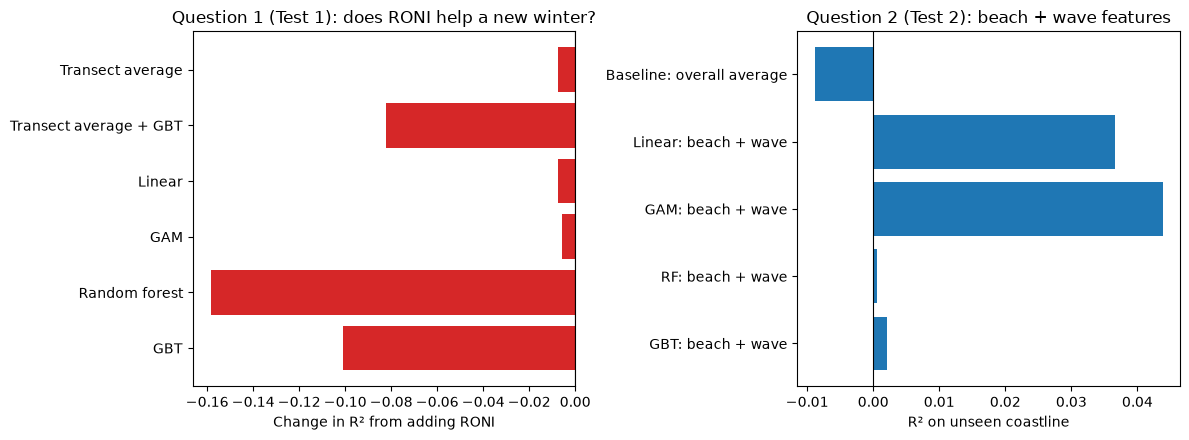

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

change = q1["Change from adding RONI"]
axes[0].barh(change.index, change.values, color=["tab:red" if v < 0 else "tab:green" for v in change.values])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()
axes[0].set_xlabel("Change in R² from adding RONI")
axes[0].set_title("Question 1 (Test 1): does RONI help a new winter?")

bw = q2.loc[[m for m in q2.index if m.endswith("beach + wave") or m.startswith("Baseline")], "R²"]
axes[1].barh(bw.index, bw.values, color="tab:blue")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].invert_yaxis()
axes[1].set_xlabel("R² on unseen coastline")
axes[1].set_title("Question 2 (Test 2): beach + wave features")

plt.tight_layout()
plt.show()

### 8c. Which features matter on unfamiliar coastline? (drop-column importance)
For each feature, retrain the model **without it** and measure how much the error on held-out coastline (Test 2) grows.
- **Positive:** the model does worse without the feature, so the feature adds real information.
- **Near zero or negative:** the model does just as well (or better) without it. Either the feature carries no information, or another feature already covers it.

We use this instead of permutation importance. Several of our features overlap strongly (wave direction and shoreline orientation; `wave_dir_sin` and `wave_dir_cos` have a correlation of −0.84). With overlapping features, the GAM learns large curves that cancel each other out, and shuffling one feature breaks that cancellation, which hugely exaggerates its importance. Dropping a feature and retraining avoids that problem.

**Expected:** about a minute.

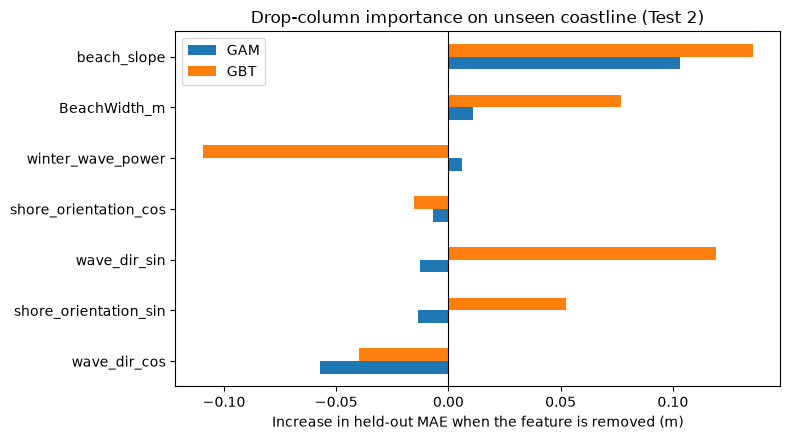

,GAM,GBT
beach_slope,0.103,0.135
BeachWidth_m,0.011,0.077
winter_wave_power,0.006,-0.109
shore_orientation_cos,-0.007,-0.015
wave_dir_sin,-0.013,0.119
shore_orientation_sin,-0.014,0.052
wave_dir_cos,-0.057,-0.040


In [28]:
def heldout_drop_importance(make_model, features):
    cv, grp = SPLITS["Test 2: new coastline"]
    def heldout_mae(feats):
        pred = cross_val_predict(make_model(), df[feats], y, groups=grp, cv=cv)
        return mean_absolute_error(y, pred)
    with_all = heldout_mae(features)
    return pd.Series({f: heldout_mae([g for g in features if g != f]) - with_all for f in features})

fixed_gbt = lambda: HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                  min_samples_leaf=500, random_state=42)
importance = pd.DataFrame({
    "GAM": heldout_drop_importance(make_gam, BEACH_WAVE),
    "GBT": heldout_drop_importance(fixed_gbt, BEACH_WAVE),
}).sort_values("GAM")

importance.plot.barh(figsize=(8, 4.5))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Increase in held-out MAE when the feature is removed (m)")
plt.title("Drop-column importance on unseen coastline (Test 2)")
plt.tight_layout()
plt.show()

importance.sort_values("GAM", ascending=False).round(3)

### 8d. Strong El Niño and La Niña winters
Our literature review predicts RONI matters most in strong events. Here's each winter's error (Test 1) for the transect average and for the transect average + linear RONI, sorted by RONI. A positive "improvement" means RONI helped that winter.

In [29]:
winter_check = pd.DataFrame({
    "winter": df["winter"],
    "RONI": df["RONI"],
    "err_transect_avg": (y - predictions[("Baseline: transect average", t1)]).abs(),
    "err_with_roni":    (y - predictions[("Transect average + linear RONI", t1)]).abs(),
    "actual": y,
})
by_winter = winter_check.groupby("winter").agg(
    RONI=("RONI", "first"),
    avg_change_m=("actual", "mean"),
    MAE_transect_avg=("err_transect_avg", "mean"),
    MAE_with_RONI=("err_with_roni", "mean"),
)
by_winter["improvement_m"] = by_winter["MAE_transect_avg"] - by_winter["MAE_with_RONI"]
by_winter.sort_values("RONI").round(2)

,RONI,avg_change_m,MAE_transect_avg,MAE_with_RONI,improvement_m
winter,,,,,
2007-2008,-1.7,-8.94,5.64,5.90,-0.26
2010-2011,-1.4,-7.23,5.64,5.72,-0.09
2020-2021,-1.3,-9.11,5.16,5.40,-0.24
2017-2018,-1.1,-4.48,5.73,5.64,0.09
2008-2009,-1.0,-5.47,5.03,4.99,0.05
2005-2006,-0.9,-8.32,5.87,5.92,-0.06
2011-2012,-0.8,-6.51,5.24,5.18,0.06
2000-2001,-0.8,-9.24,5.22,5.33,-0.11
2016-2017,-0.6,-7.81,4.95,4.97,-0.03


# 9a. Training Scores

In [30]:
# Fit each model on ALL the data, then score it on that same data = its training score
models = {"Linear": make_linear, "GAM": make_gam, "RF": make_rf, "GBT": make_gbt}

train_r2 = {}
for name, make in models.items():
    for set_name in ["beach + wave", "beach + wave + RONI"]:
        features = FEATURE_SETS[set_name]
        if name == "GBT":
            model = make().fit(df[features], y, groups=df["winter"])   # the GBT's tuning needs group labels
        else:
            model = make().fit(df[features], y)
        train_r2[(name, set_name)] = r2_score(y, model.predict(df[features]))

# 9b. Put training and test scores side by side

In [31]:
T1, T2 = "Test 1: new winter", "Test 2: new coastline"

def test_r2(name, set_name, test):
    return results[(f"{name}: {set_name}", test)]["R²"]

fit_table = pd.DataFrame({
    "Training": [train_r2[(m, "beach + wave")] for m in models],
    T1:         [test_r2(m, "beach + wave", T1) for m in models],
    T2:         [test_r2(m, "beach + wave", T2) for m in models],
}, index=list(models))

roni_table = pd.DataFrame({
    "Training without RONI": [train_r2[(m, "beach + wave")] for m in models],
    "Training with RONI":    [train_r2[(m, "beach + wave + RONI")] for m in models],
    "Test 1 without RONI":   [test_r2(m, "beach + wave", T1) for m in models],
    "Test 1 with RONI":      [test_r2(m, "beach + wave + RONI", T1) for m in models],
}, index=list(models))

fit_table.round(3)

,Training,Test 1: new winter,Test 2: new coastline
Linear,0.062,0.052,0.037
GAM,0.119,0.104,0.044
RF,0.449,0.403,0.001
GBT,0.445,0.404,0.002


# 9c. The Chart

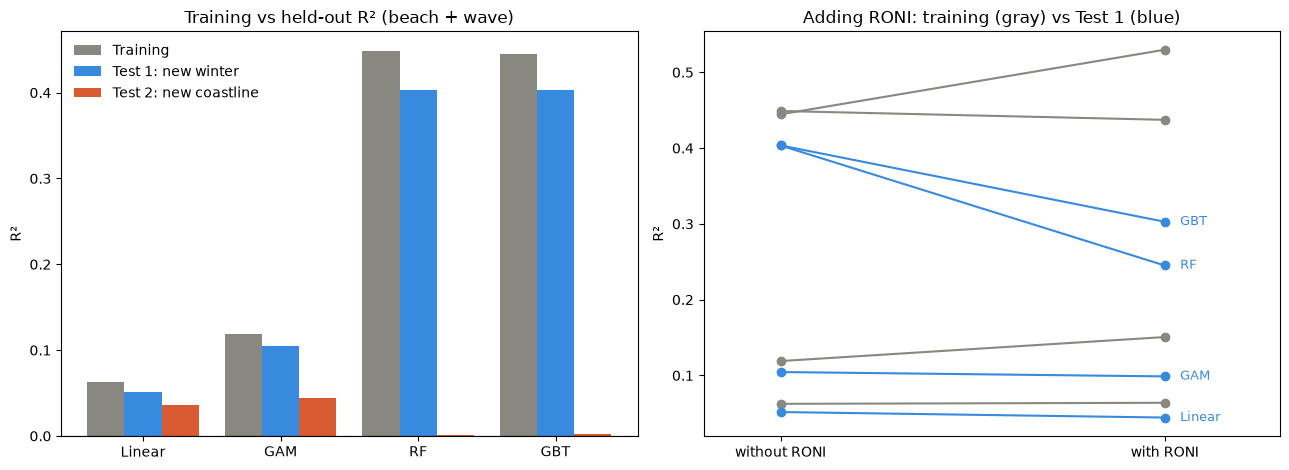

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: training vs held-out scores (beach + wave)
x = np.arange(len(fit_table))
width = 0.27
colors = ["#888780", "#378ADD", "#D85A30"]
for i, col in enumerate(fit_table.columns):
    axes[0].bar(x + (i - 1) * width, fit_table[col], width, label=col, color=colors[i])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(fit_table.index)
axes[0].set_ylabel("R²")
axes[0].set_title("Training vs held-out R² (beach + wave)")
axes[0].legend(frameon=False)

# Right: what adding RONI does to training vs Test 1 scores
for model in roni_table.index:
    row = roni_table.loc[model]
    axes[1].plot([0, 1], [row["Training without RONI"], row["Training with RONI"]], color="#888780", marker="o")
    axes[1].plot([0, 1], [row["Test 1 without RONI"], row["Test 1 with RONI"]], color="#378ADD", marker="o")
    axes[1].text(1.04, row["Test 1 with RONI"], model, va="center", fontsize=9, color="#378ADD")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["without RONI", "with RONI"])
axes[1].set_xlim(-0.2, 1.3)
axes[1].set_ylabel("R²")
axes[1].set_title("Adding RONI: training (gray) vs Test 1 (blue)")

plt.tight_layout()
plt.show()

---
# Summary of findings

### 1. RONI does not improve predictions of a new winter, in any model (Test 1)
| | Change in R² from adding RONI |
|---|---|
| Transect average → + linear RONI | −0.007 |
| Transect average → + RONI that can differ by beach type (GBT) | −0.083 |
| Linear | −0.007 |
| GAM | −0.006 |
| Random forest | −0.157 |
| Gradient-boosted tree | −0.101 |

Even asked the cleanest way (does RONI push a transect above or below its own normal?), RONI doesn't help. In the two strong El Niño winters it made errors slightly worse: 2009–10 (+0.21 m MAE) and 2015–16 (+0.10 m). The more flexible the model, the more RONI hurts, because flexible models use RONI to memorize individual winters.

### 2. A transect's own history is the strongest predictor
Predicting each transect's average change from other winters gives R² = 0.459 in Test 1. No model beats it. The random forest and gradient-boosted tree reach about 0.40 only because they recognize transects from their unique feature values.

### 3. Beach and wave features explain little about unfamiliar coastline (Test 2)
The best result is the GAM with beach features (R² 0.051); linear regression reaches 0.037. The tree models score about 0 (RF 0.004, GBT 0.006), so what they learned in Test 1 doesn't transfer to new places.

**Beach slope** is the only feature that consistently helps on unseen coastline: removing it raises held-out error by about 0.1 m in both the GAM and the GBT. Wave and orientation features overlap heavily and give mixed results.

### 4. The best model depends on the question
- Predicting a new winter at monitored transects: the **transect-average baseline**.
- Predicting unmonitored coastline from beach features: the **GAM**, though skill is small.

### How to describe this carefully
- These results are about **predictive value**: RONI, as a single number per winter, doesn't help predict winter shoreline change beyond each transect's history. They don't show that El Niño has no effect. The literature finds its effect works through waves, rainfall and timing, and our wave features are long-term averages, not each winter's actual waves.
- The sample of winters is small: 21 in total, with only two strong El Niños (2009–10 and 2015–16).
- Low R² values are expected: every feature except RONI is fixed for each transect, and satellite shorelines carry roughly ±10 m of error.

### Possible next steps
- Tune the GAM's settings (knots, smoothness) with the same nested approach used for the GBT.
- Add earlier winters (for example 1997–98) by extending the RONI file, which would give RONI more El Niño events to learn from.
- Year-by-year wave data would be the most valuable new feature, if the team decides it's worth the effort.
